**Generative AI Use**: For the purposes of the assignments, the use of generative AI is subject to the same policies regarding collaboration. Just as with other collaborators, each student must write down the solutions independently of the output of the interaction and the submission should include a note denoting the nature of the collaboration. The use of generative AI tools to substantially complete sections of the assignments is not in line with the spirit of the assignments, and would be a violation of the [Honor Code](https://communitystandards.stanford.edu/policies-and-guidance/honor-code).

---

**中文对照（参考译文，不含解答）**

**生成式 AI 的使用**：本作业对生成式 AI 的使用采用与协作相同的规则。与其他协作者交流之后，每位学生仍须独立写出自己的解答，不能直接依赖交流中得到的输出；提交时应附上说明，如实记录协作的性质。使用生成式 AI 实质性地完成作业的大部分内容，不符合本作业的教学目的，也会违反[学术诚信准则](https://communitystandards.stanford.edu/policies-and-guidance/honor-code)。

In [1]:
# CS231n local environment setup (exercise code unchanged)
# [中文] CS231n 本地环境设置。
from pathlib import Path
import os
import sys

_candidates = [Path.cwd(), *Path.cwd().parents]
_workspace = next((p for p in _candidates if (p / "requirements-local.txt").is_file()
                   and (p / "assignment1" / "cs231n").is_dir()), None)
if _workspace is None:
    raise RuntimeError("Launch Jupyter from the CS231n workspace root.")
ASSIGNMENT_DIR = _workspace / "assignment1"
os.chdir(ASSIGNMENT_DIR)
if str(ASSIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ASSIGNMENT_DIR))
print("Python:", sys.executable)
print("Working directory:", Path.cwd())


Python: D:\cs231n\.venv\Scripts\python.exe
Working directory: D:\cs231n\assignment1


# Multi-Layer Fully Connected Network
In this exercise, you will implement a fully connected network with an arbitrary number of hidden layers.

---

**中文对照（参考译文，不含解答）**

# 多层全连接网络

本练习实现隐藏层数量可配置的全连接网络。

In [2]:
# from google.colab import drive
# drive.mount('/content/drive')
# [中文] 英文原注释为挂载 Drive 的代码示例。


Read through the `FullyConnectedNet` class in the file `cs231n/classifiers/fc_net.py`.

Implement the network initialization, forward pass, and backward pass. Throughout this assignment, you will be implementing layers in `cs231n/layers.py`. You can re-use your implementations for `affine_forward`, `affine_backward`, `relu_forward`, `relu_backward`, and `softmax_loss` from before. For right now, don't worry about implementing dropout or batch/layer normalization yet, as you will add those features later.


---

**中文对照（参考译文，不含解答）**

阅读 cs231n/classifiers/fc_net.py 中的 FullyConnectedNet，实现参数初始化、前向传播和反向传播。基础层位于 cs231n/layers.py，可复用之前的 affine_forward、affine_backward、relu_forward、relu_backward 和 softmax_loss。此阶段先完成基础网络；Dropout、批归一化和层归一化会在后续加入。

In [3]:
# Setup cell.
# [中文] 环境与导入设置单元。
import time
import numpy as np
import matplotlib.pyplot as plt
from cs231n.classifiers.fc_net import *
from cs231n.data_utils import get_CIFAR10_data
from cs231n.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from cs231n.solver import Solver

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0)  # Set default size of plots.
# [中文] 设置图像的默认显示大小。
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

%load_ext autoreload
%autoreload 2

def rel_error(x, y):
    """Returns relative error."""
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

In [4]:
# Load the (preprocessed) CIFAR-10 data.
# [中文] 加载预处理后的 CIFAR-10 数据。
data = get_CIFAR10_data()
for k, v in list(data.items()):
    print(f"{k}: {v.shape}")

X_train: (49000, 3, 32, 32)
y_train: (49000,)
X_val: (1000, 3, 32, 32)
y_val: (1000,)
X_test: (1000, 3, 32, 32)
y_test: (1000,)


## Initial Loss and Gradient Check

As a sanity check, run the following to check the initial loss and to gradient check the network both with and without regularization. This is a good way to see if the initial losses seem reasonable.

For gradient checking, you should expect to see errors around 1e-7 or less.

---

**中文对照（参考译文，不含解答）**

## 初始损失与梯度检查

分别在启用和不启用正则化时检查初始损失与参数梯度。相对误差应约为 1e-7 或更小。

In [5]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
    print("Running check with reg = ", reg)
    model = FullyConnectedNet(
        [H1, H2],
        input_dim=D,
        num_classes=C,
        reg=reg,
        weight_scale=5e-2,
        dtype=np.float64
    )

    loss, grads = model.loss(X, y)
    print("Initial loss: ", loss)

    # Most of the errors should be on the order of e-7 or smaller.
    # NOTE: It is fine however to see an error for W2 on the order of e-5
    # for the check when reg = 0.0
    # [中文] 多数相对误差应在 1e-7 或更小量级。当 reg=0.0 时，W2 的检查误差达到 1e-5 量级也可以接受。
    for name in sorted(grads):
        f = lambda _: model.loss(X, y)[0]
        grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
        print(f"{name} relative error: {rel_error(grad_num, grads[name])}")

Running check with reg =  0
Initial loss:  2.300479089768492
W1 relative error: 1.0252674471656573e-07
W2 relative error: 2.2120479295080622e-05
W3 relative error: 4.5623278736665505e-07
b1 relative error: 4.6600944653202505e-09
b2 relative error: 2.085654276112763e-09
b3 relative error: 1.689724888469736e-10
Running check with reg =  3.14
Initial loss:  7.052114776533016
W1 relative error: 3.904541941902138e-09
W2 relative error: 6.86942277940646e-08
W3 relative error: 3.483989247437803e-08
b1 relative error: 1.4752427965311745e-08
b2 relative error: 1.4615869332918208e-09
b3 relative error: 1.3200479211447775e-10


As another sanity check, make sure your network can overfit on a small dataset of 50 images. First, we will try a three-layer network with 100 units in each hidden layer. In the following cell, tweak the **learning rate** and **weight initialization scale** to overfit and achieve 100% training accuracy within 20 epochs.

---

**中文对照（参考译文，不含解答）**

再检查模型能否过拟合 50 张图片的小数据集。先使用三层网络，每个隐藏层含 100 个单元，只调整学习率和权重初始化尺度，争取在 20 个 epoch 内达到 100% 训练准确率。

(Iteration 1 / 40) loss: 2.329114
(Epoch 0 / 20) train acc: 0.220000; val_acc: 0.111000
(Epoch 1 / 20) train acc: 0.380000; val_acc: 0.116000
(Epoch 2 / 20) train acc: 0.420000; val_acc: 0.106000
(Epoch 3 / 20) train acc: 0.680000; val_acc: 0.169000
(Epoch 4 / 20) train acc: 0.700000; val_acc: 0.172000
(Epoch 5 / 20) train acc: 0.400000; val_acc: 0.147000
(Iteration 11 / 40) loss: 1.243452
(Epoch 6 / 20) train acc: 0.760000; val_acc: 0.155000
(Epoch 7 / 20) train acc: 0.820000; val_acc: 0.173000
(Epoch 8 / 20) train acc: 0.820000; val_acc: 0.201000
(Epoch 9 / 20) train acc: 0.820000; val_acc: 0.171000
(Epoch 10 / 20) train acc: 0.940000; val_acc: 0.188000
(Iteration 21 / 40) loss: 0.299133
(Epoch 11 / 20) train acc: 0.900000; val_acc: 0.195000
(Epoch 12 / 20) train acc: 0.960000; val_acc: 0.191000
(Epoch 13 / 20) train acc: 0.920000; val_acc: 0.195000
(Epoch 14 / 20) train acc: 0.940000; val_acc: 0.213000
(Epoch 15 / 20) train acc: 1.000000; val_acc: 0.205000
(Iteration 31 / 40) loss: 

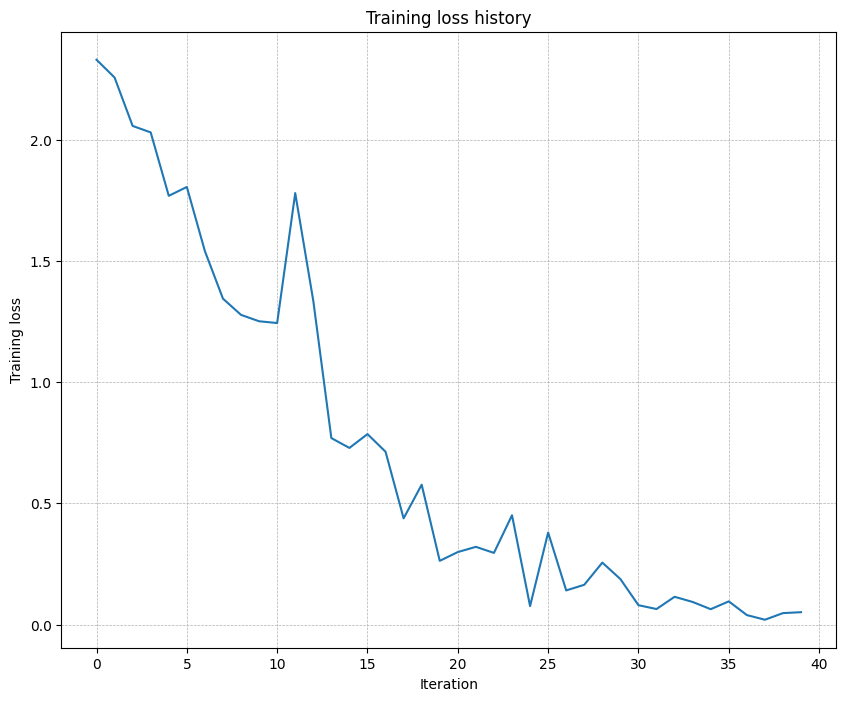

In [26]:
# TODO: Use a three-layer Net to overfit 50 training examples by
# tweaking just the learning rate and initialization scale.
# [中文] 待完成：只调整学习率和权重初始化尺度，使三层网络过拟合这 50 个训练样本。

num_train = 50
small_data = {
  "X_train": data["X_train"][:num_train],
  "y_train": data["y_train"][:num_train],
  "X_val": data["X_val"],
  "y_val": data["y_val"],
}

weight_scale = 1e-2   # Experiment with this!
# [中文] 可以尝试调整这个值并观察结果。
learning_rate = 1e-2  # Experiment with this!
# [中文] 可以尝试调整这个值并观察结果。


model = FullyConnectedNet(
    [100, 100],
    weight_scale=weight_scale,
    dtype=np.float64
)
solver = Solver(
    model,
    small_data,
    print_every=10,
    num_epochs=20,
    batch_size=25,
    update_rule="sgd",
    optim_config={"learning_rate": learning_rate},
)
solver.train()

plt.plot(solver.loss_history)
plt.title("Training loss history")
plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.grid(linestyle='--', linewidth=0.5)
plt.show()

Now, try to use a five-layer network with 100 units on each layer to overfit on 50 training examples. Again, you will have to adjust the learning rate and weight initialization scale, but you should be able to achieve 100% training accuracy within 20 epochs.

---

**中文对照（参考译文，不含解答）**

然后使用五层网络，每个隐藏层含 100 个单元，仍用这 50 个训练样本。调整学习率与权重初始化尺度，争取在 20 个 epoch 内达到 100% 训练准确率。

(Iteration 1 / 40) loss: 121.473668
(Epoch 0 / 20) train acc: 0.140000; val_acc: 0.120000
(Epoch 1 / 20) train acc: 0.160000; val_acc: 0.079000
(Epoch 2 / 20) train acc: 0.280000; val_acc: 0.143000
(Epoch 3 / 20) train acc: 0.440000; val_acc: 0.129000
(Epoch 4 / 20) train acc: 0.680000; val_acc: 0.125000
(Epoch 5 / 20) train acc: 0.760000; val_acc: 0.114000
(Iteration 11 / 40) loss: 3.332528
(Epoch 6 / 20) train acc: 0.740000; val_acc: 0.125000
(Epoch 7 / 20) train acc: 0.840000; val_acc: 0.125000
(Epoch 8 / 20) train acc: 0.920000; val_acc: 0.129000
(Epoch 9 / 20) train acc: 0.980000; val_acc: 0.148000
(Epoch 10 / 20) train acc: 0.980000; val_acc: 0.140000
(Iteration 21 / 40) loss: 0.076967
(Epoch 11 / 20) train acc: 1.000000; val_acc: 0.143000
(Epoch 12 / 20) train acc: 1.000000; val_acc: 0.145000
(Epoch 13 / 20) train acc: 1.000000; val_acc: 0.145000
(Epoch 14 / 20) train acc: 1.000000; val_acc: 0.145000
(Epoch 15 / 20) train acc: 1.000000; val_acc: 0.146000
(Iteration 31 / 40) loss

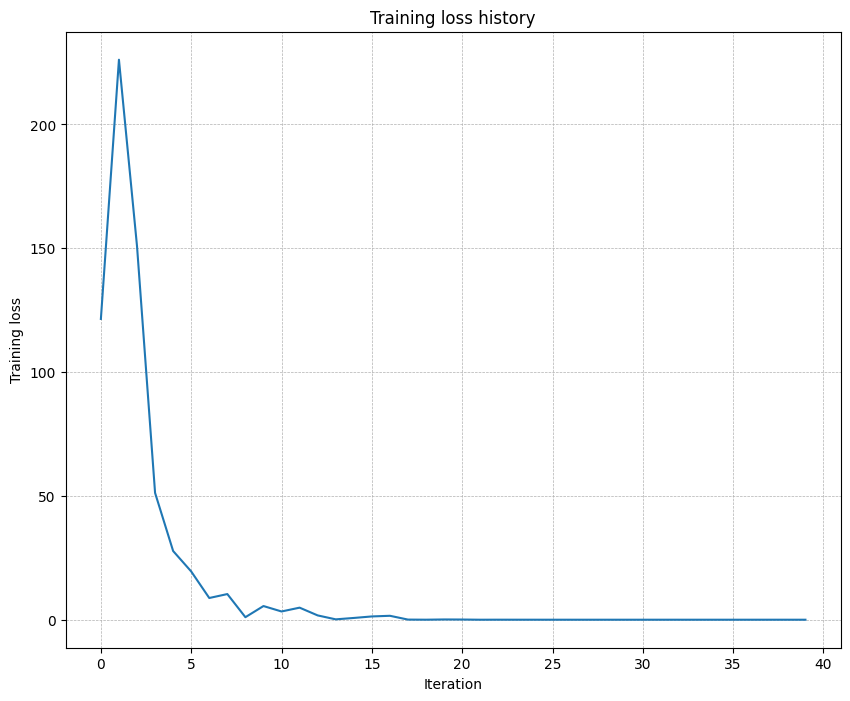

In [31]:
# TODO: Use a five-layer Net to overfit 50 training examples by
# tweaking just the learning rate and initialization scale.
# [中文] 待完成：只调整学习率和权重初始化尺度，使五层网络过拟合这 50 个训练样本。

num_train = 50
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

learning_rate = 2e-3  # Experiment with this!
# [中文] 可以尝试调整这个值并观察结果。
weight_scale = 1e-1   # Experiment with this!
# [中文] 可以尝试调整这个值并观察结果。


model = FullyConnectedNet(
    [100, 100, 100, 100],
    weight_scale=weight_scale,
    dtype=np.float64
)
solver = Solver(
    model,
    small_data,
    print_every=10,
    num_epochs=20,
    batch_size=25,
    update_rule='sgd',
    optim_config={'learning_rate': learning_rate},
)
solver.train()

plt.plot(solver.loss_history)
plt.title('Training loss history')
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.grid(linestyle='--', linewidth=0.5)
plt.show()

## Inline Question 1:
Did you notice anything about the comparative difficulty of training the three-layer network vs. training the five-layer network? In particular, based on your experience, which network seemed more sensitive to the initialization scale? Why do you think that is the case?

## Answer:
[FILL THIS IN]




---

**中文对照（参考译文，不含解答）**

## 随堂问题 1

比较训练三层网络与五层网络的难度时，你观察到了什么？根据你的实验，哪个网络对权重初始化尺度更敏感？你认为原因是什么？

**你的回答：** 我认为训练三层网络时调参更轻松。五层网络对权重初始化尺度更敏感，因为尺度缩放逐层积累，层数越多，尺度的影响越明显。

# Update rules
So far we have used vanilla stochastic gradient descent (SGD) as our update rule. More sophisticated update rules can make it easier to train deep networks. We will implement a few of the most commonly used update rules and compare them to vanilla SGD.

---

**中文对照（参考译文，不含解答）**

# 参数更新规则

此前使用普通随机梯度下降（SGD）。接下来实现几种常用优化方法，并比较它们训练深层网络的效果。

## SGD+Momentum
Stochastic gradient descent with momentum is a widely used update rule that tends to make deep networks converge faster than vanilla stochastic gradient descent. See the Momentum Update section at http://cs231n.github.io/neural-networks-3/#sgd for more information.

Open the file `cs231n/optim.py` and read the documentation at the top of the file to make sure you understand the API. Implement the SGD+momentum update rule in the function `sgd_momentum` and run the following to check your implementation. You should see errors less than e-8.

---

**中文对照（参考译文，不含解答）**

## 带动量的 SGD

动量通常有助于加快深层网络收敛，课程讲义链接见英文原文。先阅读 cs231n/optim.py 顶部的接口说明，再实现 sgd_momentum，并运行下方检查；误差应小于 1e-8。

In [33]:
from cs231n.optim import sgd_momentum

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
v = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {"learning_rate": 1e-3, "velocity": v}
next_w, _ = sgd_momentum(w, dw, config=config)

expected_next_w = np.asarray([
  [ 0.1406,      0.20738947,  0.27417895,  0.34096842,  0.40775789],
  [ 0.47454737,  0.54133684,  0.60812632,  0.67491579,  0.74170526],
  [ 0.80849474,  0.87528421,  0.94207368,  1.00886316,  1.07565263],
  [ 1.14244211,  1.20923158,  1.27602105,  1.34281053,  1.4096    ]])
expected_velocity = np.asarray([
  [ 0.5406,      0.55475789,  0.56891579, 0.58307368,  0.59723158],
  [ 0.61138947,  0.62554737,  0.63970526,  0.65386316,  0.66802105],
  [ 0.68217895,  0.69633684,  0.71049474,  0.72465263,  0.73881053],
  [ 0.75296842,  0.76712632,  0.78128421,  0.79544211,  0.8096    ]])

# Should see relative errors around e-8 or less
# [中文] 相对误差应约为 1e-8 或更小。
print("next_w error: ", rel_error(next_w, expected_next_w))
print("velocity error: ", rel_error(expected_velocity, config["velocity"]))

next_w error:  8.882347033505819e-09
velocity error:  4.269287743278663e-09


Once you have done so, run the following to train a six-layer network with both SGD and SGD+momentum. You should see the SGD+momentum update rule converge faster.

---

**中文对照（参考译文，不含解答）**

完成后，用普通 SGD 和带动量的 SGD 分别训练六层网络，比较收敛速度；题目预期带动量的版本收敛更快。

Running with  sgd
(Iteration 1 / 200) loss: 2.743793
(Epoch 0 / 5) train acc: 0.116000; val_acc: 0.107000
(Iteration 11 / 200) loss: 2.282198
(Iteration 21 / 200) loss: 2.307090
(Iteration 31 / 200) loss: 2.136873
(Epoch 1 / 5) train acc: 0.219000; val_acc: 0.235000
(Iteration 41 / 200) loss: 2.129920
(Iteration 51 / 200) loss: 2.052462
(Iteration 61 / 200) loss: 2.029775
(Iteration 71 / 200) loss: 2.041690
(Epoch 2 / 5) train acc: 0.280000; val_acc: 0.264000
(Iteration 81 / 200) loss: 1.938080
(Iteration 91 / 200) loss: 2.035328
(Iteration 101 / 200) loss: 1.994687
(Iteration 111 / 200) loss: 1.956516
(Epoch 3 / 5) train acc: 0.296000; val_acc: 0.266000
(Iteration 121 / 200) loss: 1.890959
(Iteration 131 / 200) loss: 1.917408
(Iteration 141 / 200) loss: 1.859378
(Iteration 151 / 200) loss: 1.784854
(Epoch 4 / 5) train acc: 0.320000; val_acc: 0.291000
(Iteration 161 / 200) loss: 1.886635
(Iteration 171 / 200) loss: 1.797196
(Iteration 181 / 200) loss: 1.934308
(Iteration 191 / 200) los

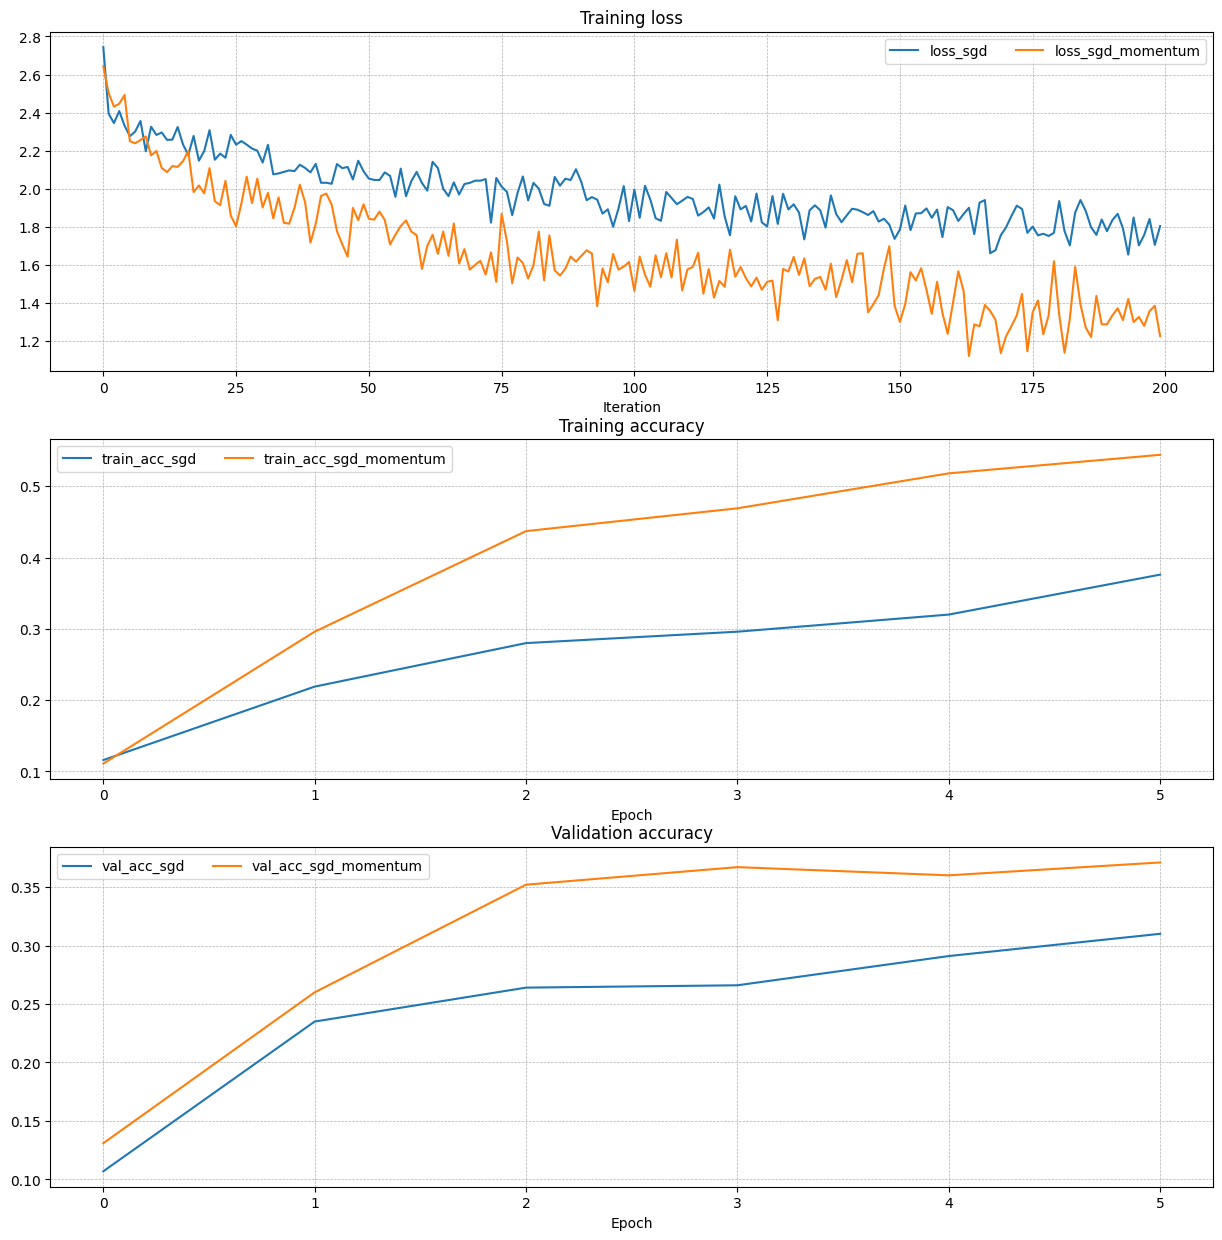

In [34]:
num_train = 4000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

solvers = {}

for update_rule in ['sgd', 'sgd_momentum']:
    print('Running with ', update_rule)
    model = FullyConnectedNet(
        [100, 100, 100, 100, 100],
        weight_scale=5e-2
    )

    solver = Solver(
        model,
        small_data,
        num_epochs=5,
        batch_size=100,
        update_rule=update_rule,
        optim_config={'learning_rate': 5e-3},
        verbose=True,
    )
    solvers[update_rule] = solver
    solver.train()

fig, axes = plt.subplots(3, 1, figsize=(15, 15))

axes[0].set_title('Training loss')
axes[0].set_xlabel('Iteration')
axes[1].set_title('Training accuracy')
axes[1].set_xlabel('Epoch')
axes[2].set_title('Validation accuracy')
axes[2].set_xlabel('Epoch')

for update_rule, solver in solvers.items():
    axes[0].plot(solver.loss_history, label=f"loss_{update_rule}")
    axes[1].plot(solver.train_acc_history, label=f"train_acc_{update_rule}")
    axes[2].plot(solver.val_acc_history, label=f"val_acc_{update_rule}")

for ax in axes:
    ax.legend(loc="best", ncol=4)
    ax.grid(linestyle='--', linewidth=0.5)

plt.show()

## RMSProp and Adam
RMSProp [1] and Adam [2] are update rules that set per-parameter learning rates by using a running average of the second moments of gradients.

In the file `cs231n/optim.py`, implement the RMSProp update rule in the `rmsprop` function and implement the Adam update rule in the `adam` function, and check your implementations using the tests below.

**NOTE:** Please implement the _complete_ Adam update rule (with the bias correction mechanism), not the first simplified version mentioned in the course notes.

[1] Tijmen Tieleman and Geoffrey Hinton. "Lecture 6.5-rmsprop: Divide the gradient by a running average of its recent magnitude." COURSERA: Neural Networks for Machine Learning 4 (2012).

[2] Diederik Kingma and Jimmy Ba, "Adam: A Method for Stochastic Optimization", ICLR 2015.

---

**中文对照（参考译文，不含解答）**

## RMSProp 与 Adam

RMSProp 和 Adam 利用梯度二阶矩的移动平均，为各参数调整有效学习率。分别在 cs231n/optim.py 中完成 rmsprop 和 adam，并运行下方检查。Adam 必须包含偏差修正，不能只实现讲义中最初介绍的简化版本。论文信息保留在英文原文中。

In [36]:
# Test RMSProp implementation
# [中文] 测试 RMSProp 的实现。
from cs231n.optim import rmsprop

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
cache = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'cache': cache}
next_w, _ = rmsprop(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.39223849, -0.34037513, -0.28849239, -0.23659121, -0.18467247],
  [-0.132737,   -0.08078555, -0.02881884,  0.02316247,  0.07515774],
  [ 0.12716641,  0.17918792,  0.23122175,  0.28326742,  0.33532447],
  [ 0.38739248,  0.43947102,  0.49155973,  0.54365823,  0.59576619]])
expected_cache = np.asarray([
  [ 0.5976,      0.6126277,   0.6277108,   0.64284931,  0.65804321],
  [ 0.67329252,  0.68859723,  0.70395734,  0.71937285,  0.73484377],
  [ 0.75037008,  0.7659518,   0.78158892,  0.79728144,  0.81302936],
  [ 0.82883269,  0.84469141,  0.86060554,  0.87657507,  0.8926    ]])

# You should see relative errors around e-7 or less
# [中文] 相对误差应约为 1e-7 或更小。
print('next_w error: ', rel_error(expected_next_w, next_w))
print('cache error: ', rel_error(expected_cache, config['cache']))

next_w error:  9.524687511038133e-08
cache error:  2.6477955807156126e-09


In [37]:
# Test Adam implementation
# [中文] 测试 Adam 的实现。
from cs231n.optim import adam

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
m = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)
v = np.linspace(0.7, 0.5, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'm': m, 'v': v, 't': 5}
next_w, _ = adam(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.40094747, -0.34836187, -0.29577703, -0.24319299, -0.19060977],
  [-0.1380274,  -0.08544591, -0.03286534,  0.01971428,  0.0722929],
  [ 0.1248705,   0.17744702,  0.23002243,  0.28259667,  0.33516969],
  [ 0.38774145,  0.44031188,  0.49288093,  0.54544852,  0.59801459]])
expected_v = np.asarray([
  [ 0.69966,     0.68908382,  0.67851319,  0.66794809,  0.65738853,],
  [ 0.64683452,  0.63628604,  0.6257431,   0.61520571,  0.60467385,],
  [ 0.59414753,  0.58362676,  0.57311152,  0.56260183,  0.55209767,],
  [ 0.54159906,  0.53110598,  0.52061845,  0.51013645,  0.49966,   ]])
expected_m = np.asarray([
  [ 0.48,        0.49947368,  0.51894737,  0.53842105,  0.55789474],
  [ 0.57736842,  0.59684211,  0.61631579,  0.63578947,  0.65526316],
  [ 0.67473684,  0.69421053,  0.71368421,  0.73315789,  0.75263158],
  [ 0.77210526,  0.79157895,  0.81105263,  0.83052632,  0.85      ]])

# You should see relative errors around e-7 or less
# [中文] 相对误差应约为 1e-7 或更小。
print('next_w error: ', rel_error(expected_next_w, next_w))
print('v error: ', rel_error(expected_v, config['v']))
print('m error: ', rel_error(expected_m, config['m']))

next_w error:  1.1395691798535431e-07
v error:  4.208314038113071e-09
m error:  4.214963193114416e-09


Once you have debugged your RMSProp and Adam implementations, run the following to train a pair of deep networks using these new update rules:

---

**中文对照（参考译文，不含解答）**

确认 RMSProp、Adam 实现通过检查后，用它们分别训练深层网络并比较结果。

Running with  adam
(Iteration 1 / 200) loss: 2.660482
(Epoch 0 / 5) train acc: 0.133000; val_acc: 0.153000
(Iteration 11 / 200) loss: 1.940001
(Iteration 21 / 200) loss: 1.848977
(Iteration 31 / 200) loss: 1.746091
(Epoch 1 / 5) train acc: 0.401000; val_acc: 0.331000
(Iteration 41 / 200) loss: 1.641283
(Iteration 51 / 200) loss: 1.645197
(Iteration 61 / 200) loss: 1.934129
(Iteration 71 / 200) loss: 1.620686
(Epoch 2 / 5) train acc: 0.437000; val_acc: 0.350000
(Iteration 81 / 200) loss: 1.598219
(Iteration 91 / 200) loss: 1.608577
(Iteration 101 / 200) loss: 1.690657
(Iteration 111 / 200) loss: 1.500594
(Epoch 3 / 5) train acc: 0.489000; val_acc: 0.365000
(Iteration 121 / 200) loss: 1.304994
(Iteration 131 / 200) loss: 1.453834
(Iteration 141 / 200) loss: 1.560761
(Iteration 151 / 200) loss: 1.425052
(Epoch 4 / 5) train acc: 0.581000; val_acc: 0.374000
(Iteration 161 / 200) loss: 1.285433
(Iteration 171 / 200) loss: 1.336846
(Iteration 181 / 200) loss: 1.230096
(Iteration 191 / 200) lo

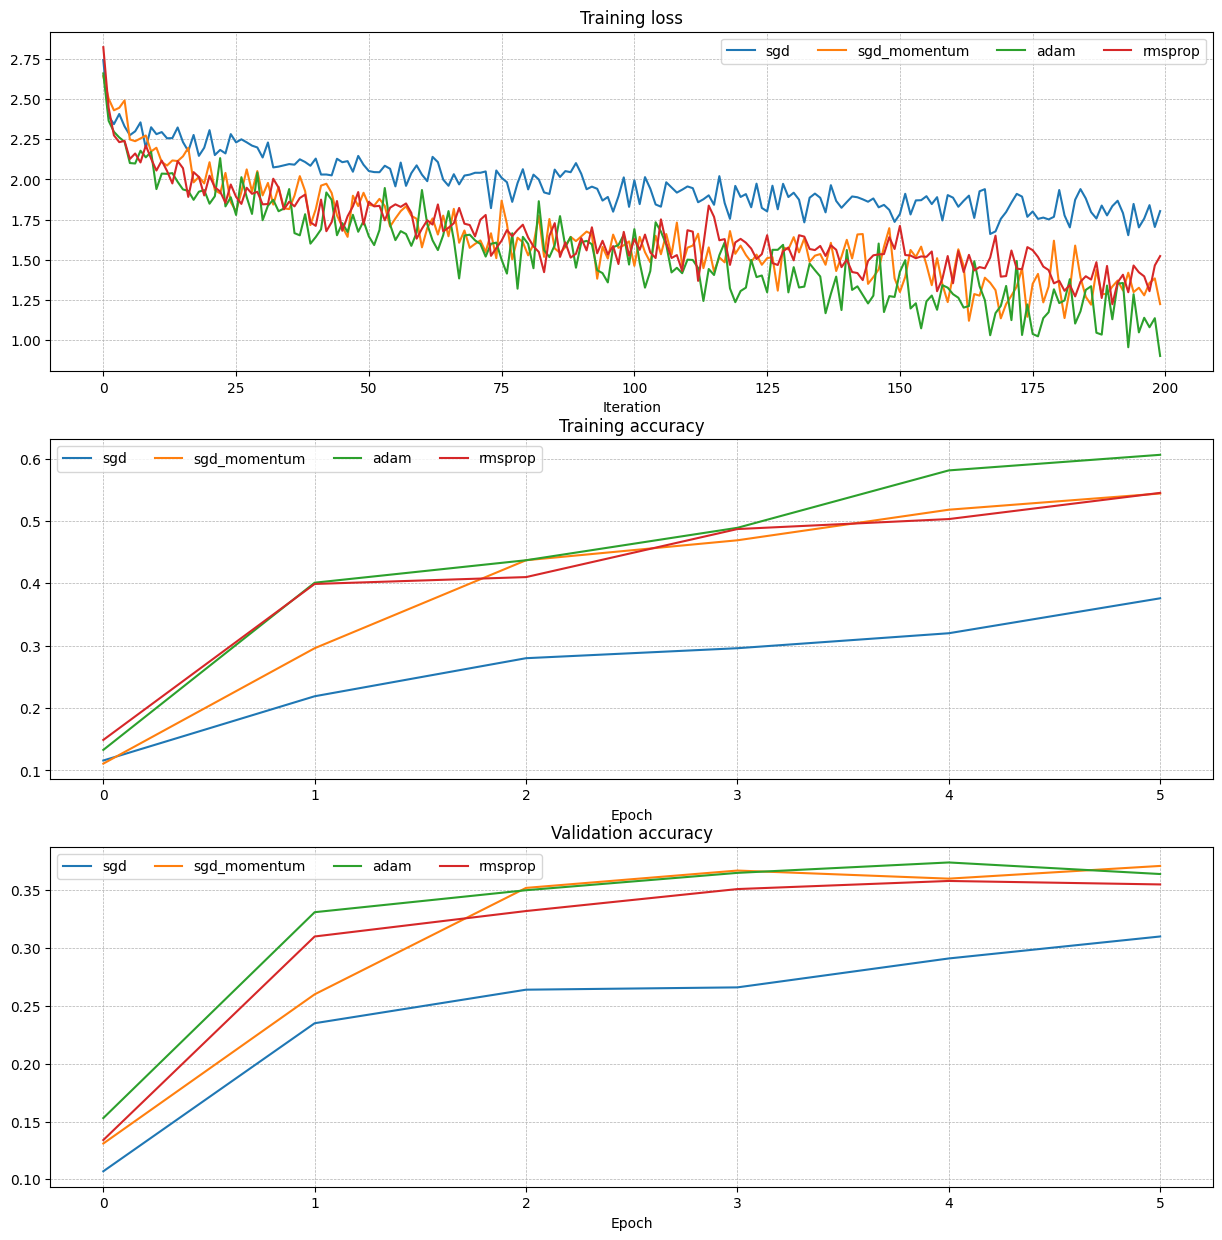

In [38]:
learning_rates = {'rmsprop': 1e-4, 'adam': 1e-3}
for update_rule in ['adam', 'rmsprop']:
    print('Running with ', update_rule)
    model = FullyConnectedNet(
        [100, 100, 100, 100, 100],
        weight_scale=5e-2
    )
    solver = Solver(
        model,
        small_data,
        num_epochs=5,
        batch_size=100,
        update_rule=update_rule,
        optim_config={'learning_rate': learning_rates[update_rule]},
        verbose=True
    )
    solvers[update_rule] = solver
    solver.train()
    print()

fig, axes = plt.subplots(3, 1, figsize=(15, 15))

axes[0].set_title('Training loss')
axes[0].set_xlabel('Iteration')
axes[1].set_title('Training accuracy')
axes[1].set_xlabel('Epoch')
axes[2].set_title('Validation accuracy')
axes[2].set_xlabel('Epoch')

for update_rule, solver in solvers.items():
    axes[0].plot(solver.loss_history, label=f"{update_rule}")
    axes[1].plot(solver.train_acc_history, label=f"{update_rule}")
    axes[2].plot(solver.val_acc_history, label=f"{update_rule}")

for ax in axes:
    ax.legend(loc='best', ncol=4)
    ax.grid(linestyle='--', linewidth=0.5)

plt.show()

## Inline Question 2:

AdaGrad, like Adam, is a per-parameter optimization method that uses the following update rule:

```
cache += dw**2
w += - learning_rate * dw / (np.sqrt(cache) + eps)
```

John notices that when he was training a network with AdaGrad that the updates became very small, and that his network was learning slowly. Using your knowledge of the AdaGrad update rule, why do you think the updates would become very small? Would Adam have the same issue?


## Answer:
[FILL THIS IN]




---

**中文对照（参考译文，不含解答）**

## 随堂问题 2

与 Adam 类似，AdaGrad 是一种为每个参数分别调整更新步长的优化方法，其更新规则如下：

```
cache += dw**2
w += - learning_rate * dw / (np.sqrt(cache) + eps)
```

John 用 AdaGrad 训练网络时，发现参数更新变得很小，网络学习速度也很慢。根据 AdaGrad 的更新规则，你认为更新为什么会变小？Adam 也会出现相同的问题吗？

**你的回答：** AdaGrad 会不断累加历史梯度的平方，使更新公式的分母逐渐增大，更新步长越来越小，而Adam使用的beta2让旧梯度的影响逐渐衰减，很难出现相同问题

# Train a Good Model!
Train the best fully connected model that you can on CIFAR-10, storing your best model in the `best_model` variable. We require you to get at least 50% accuracy on the validation set using a fully connected network.

If you are careful it should be possible to get accuracies above 55%, but we don't require it for this part and won't assign extra credit for doing so. Later in the next assignment, we will ask you to train the best convolutional network that you can on CIFAR-10, and we would prefer that you spend your effort working on convolutional networks rather than fully connected networks.

**Note:** In the next assignment, you will learn techniques like BatchNormalization and Dropout which can help you train powerful models.

---

**中文对照（参考译文，不含解答）**

# 训练表现良好的模型

在 CIFAR-10 上训练全连接网络，将验证表现最佳的模型保存为 best_model。要求验证准确率至少达到 50%。超过 55% 可作为进一步尝试的目标，但本部分不会为此额外加分。后续作业会训练卷积网络，因此无需在此无限调参。批归一化和 Dropout 会在下一份作业中详细学习。

In [61]:
best_model = None

################################################################################
# TODO: Train the best FullyConnectedNet that you can on CIFAR-10. You might   #
# find batch/layer normalization and dropout useful. Store your best model in  #
# the best_model variable.                                                     #
################################################################################
# *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
# [中文] 待完成：在 CIFAR-10 上训练表现尽可能好的 FullyConnectedNet，将最佳模型存入 best_model。原题提示：批归一化、层归一化或 Dropout
# 可能有帮助。保留原有代码区域标记。
model = FullyConnectedNet(
        [100, 100, 100, 100, 100],
        weight_scale=5e-2
    )
solver = Solver(
    model,
    data,
    num_epochs=7,
    batch_size=100,
    update_rule='adam',
    optim_config={'learning_rate': 7e-4},
    print_every=500,
    verbose=True
)

solver.train()

best_model = solver.model
# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
################################################################################
#                              END OF YOUR CODE                                #
################################################################################
# [中文] 原代码区域结束标记，请勿删除或修改。


(Iteration 1 / 3430) loss: 2.462699
(Epoch 0 / 7) train acc: 0.128000; val_acc: 0.120000
(Epoch 1 / 7) train acc: 0.419000; val_acc: 0.433000
(Iteration 501 / 3430) loss: 1.620079
(Epoch 2 / 7) train acc: 0.479000; val_acc: 0.476000
(Iteration 1001 / 3430) loss: 1.337699
(Epoch 3 / 7) train acc: 0.508000; val_acc: 0.496000
(Iteration 1501 / 3430) loss: 1.390077
(Epoch 4 / 7) train acc: 0.547000; val_acc: 0.510000
(Iteration 2001 / 3430) loss: 1.052301
(Epoch 5 / 7) train acc: 0.571000; val_acc: 0.506000
(Iteration 2501 / 3430) loss: 1.295457
(Epoch 6 / 7) train acc: 0.566000; val_acc: 0.523000
(Iteration 3001 / 3430) loss: 1.183776
(Epoch 7 / 7) train acc: 0.553000; val_acc: 0.520000


# Test Your Model!
Run your best model on the validation and test sets. You should achieve at least 50% accuracy on the validation set and the test set.

---

**中文对照（参考译文，不含解答）**

# 评估模型

在验证集和测试集上运行选出的模型，两者准确率都应至少达到 50%。

In [62]:
y_test_pred = np.argmax(best_model.loss(data['X_test']), axis=1)
y_val_pred = np.argmax(best_model.loss(data['X_val']), axis=1)
print('Validation set accuracy: ', (y_val_pred == data['y_val']).mean())
print('Test set accuracy: ', (y_test_pred == data['y_test']).mean())

Validation set accuracy:  0.523
Test set accuracy:  0.503
